In [1]:
# ================================================
# TAHAP 1: Import Library & Setup Environment
# ================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import torch # CTGAN berjalan di atas PyTorch

# --- Scikit-Learn untuk Pemrosesan Data & Evaluasi ---
from sklearn.model_selection import train_test_split # PENTING: dipanggil di awal untuk strategi baru
from sklearn.preprocessing import MinMaxScaler, RobustScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# --- TensorFlow/Keras untuk Deep Learning ---
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import plot_model

# --- CTGAN untuk Pembuatan Data Sintetis ---
from ctgan import CTGAN

# --- Pengaturan Lingkungan ---
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set(style="whitegrid")

print("Semua libraries berhasil di-import dan siap digunakan!")

Semua libraries berhasil di-import dan siap digunakan!


In [2]:
# ================================================
# TAHAP 2: Load Data Target (Imbalanced Dataset)
# ================================================

# Menggunakan local path sesuai direktori kerja
BASE_PATH = 'CIC_Dataset/' 
file_name = '02-20-2018.csv' # Langsung gunakan file yang berisi serangan DDoS LOIC-HTTP

file_path = BASE_PATH + file_name

print("Sedang memuat data, mohon tunggu...")
# Load data
df = pd.read_csv(file_path)

# PENTING: Bersihkan spasi berlebih pada nama kolom (Khas dataset CIC-IDS)
df.columns = df.columns.str.strip()

print(f"Data berhasil di-load!")
print(f"File: {file_name}")
print(f"Jumlah baris (records): {df.shape[0]:,}")
print(f"Jumlah kolom (fitur): {df.shape[1]}")

# Cek seberapa parah ketimpangan datanya
print("\nDistribusi Label Asli:")
print(df['Label'].value_counts())

Sedang memuat data, mohon tunggu...
Data berhasil di-load!
File: 02-20-2018.csv
Jumlah baris (records): 7,948,748
Jumlah kolom (fitur): 84

Distribusi Label Asli:
Label
Benign                    7372557
DDoS attacks-LOIC-HTTP     576191
Name: count, dtype: int64


=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7948748 entries, 0 to 7948747
Data columns (total 84 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Flow ID            object 
 1   Src IP             object 
 2   Src Port           int64  
 3   Dst IP             object 
 4   Dst Port           int64  
 5   Protocol           int64  
 6   Timestamp          object 
 7   Flow Duration      int64  
 8   Tot Fwd Pkts       int64  
 9   Tot Bwd Pkts       int64  
 10  TotLen Fwd Pkts    float64
 11  TotLen Bwd Pkts    float64
 12  Fwd Pkt Len Max    float64
 13  Fwd Pkt Len Min    float64
 14  Fwd Pkt Len Mean   float64
 15  Fwd Pkt Len Std    float64
 16  Bwd Pkt Len Max    float64
 17  Bwd Pkt Len Min    float64
 18  Bwd Pkt Len Mean   float64
 19  Bwd Pkt Len Std    float64
 20  Flow Byts/s        float64
 21  Flow Pkts/s        float64
 22  Flow IAT Mean      float64
 23  Flow IAT Std       float64
 24  Flow IAT Max       float

,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,Fwd Pkt Len Std,Bwd Pkt Len Max,Bwd Pkt Len Min,Bwd Pkt Len Mean,Bwd Pkt Len Std,Flow Byts/s,Flow Pkts/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Tot,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Tot,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Len,Bwd Header Len,Fwd Pkts/s,Bwd Pkts/s,Pkt Len Min,Pkt Len Max,Pkt Len Mean,Pkt Len Std,Pkt Len Var,FIN Flag Cnt,SYN Flag Cnt,RST Flag Cnt,PSH Flag Cnt,ACK Flag Cnt,URG Flag Cnt,CWE Flag Count,ECE Flag Cnt,Down/Up Ratio,Pkt Size Avg,Fwd Seg Size Avg,Bwd Seg Size Avg,Fwd Byts/b Avg,Fwd Pkts/b Avg,Fwd Blk Rate Avg,Bwd Byts/b Avg,Bwd Pkts/b Avg,Bwd Blk Rate Avg,Subflow Fwd Pkts,Subflow Fwd Byts,Subflow Bwd Pkts,Subflow Bwd Byts,Init Fwd Win Byts,Init Bwd Win Byts,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,172.31.69.25-94.231.103.172-22-45498-6,94.231.103.172,45498,172.31.69.25,22,6,20/02/2018 08:34:07,888751,11,11,1249.00,1969.00,736.00,0.00,113.55,220.90,976.00,0.00,179.00,364.19,3620.81,24.75,42321.48,47851.74,101609.00,14.00,888751.00,88875.10,49295.74,140273.00,14.00,788197.00,78819.70,55863.19,139285.00,72.00,0,0,0,0,360,360,12.38,12.38,0.00,976.00,139.91,290.63,84468.08,0,0,0,1,0,0,0,0,1.00,146.27,113.55,179.00,0,0,0,0,0,0,11,1249,11,1969,14600,233,7,32,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Benign
1,8.0.6.4-8.6.0.1-0-0-0,8.6.0.1,0,8.0.6.4,0,0,20/02/2018 08:33:22,112642816,3,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.03,56300000.00,7.07,56300000.00,56300000.00,113000000.00,56300000.00,7.07,56300000.00,56300000.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0.03,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0,0,0,0,0,0,3,0,0,0,-1,-1,0,0,0.00,0.00,0.00,0.00,56300000.00,7.07,56300000.00,56300000.00,Benign
2,8.0.6.4-8.6.0.1-0-0-0,8.6.0.1,0,8.0.6.4,0,0,20/02/2018 08:36:11,112642712,3,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.03,56300000.00,18.38,56300000.00,56300000.00,113000000.00,56300000.00,18.38,56300000.00,56300000.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0.03,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0,0,0,0,0,0,3,0,0,0,-1,-1,0,0,0.00,0.00,0.00,0.00,56300000.00,18.38,56300000.00,56300000.00,Benign
3,8.0.6.4-8.6.0.1-0-0-0,8.6.0.1,0,8.0.6.4,0,0,20/02/2018 08:39:00,112642648,3,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.03,56300000.00,5.66,56300000.00,56300000.00,113000000.00,56300000.00,5.66,56300000.00,56300000.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0.03,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0,0,0,0,0,0,3,0,0,0,-1,-1,0,0,0.00,0.00,0.00,0.00,56300000.00,5.66,56300000.00,56300000.00,Benign
4,8.0.6.4-8.6.0.1-0-0-0,8.6.0.1,0,8.0.6.4,0,0,20/02/2018 08:41:49,112642702,3,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.03,56300000.00,65.05,56300000.00,56300000.00,113000000.00,56300000.00,65.05,56300000.00,56300000.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0.03,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0,0,0,0,0,0,3,0,0,0,-1,-1,0,0,0.00,0.00,0.00,0.00,56300000.00,65.05,56300000.00,56300000.00,Benign



=== Distribusi Kelas (Label) ===
Label
Benign                    7372557
DDoS attacks-LOIC-HTTP     576191
Name: count, dtype: int64


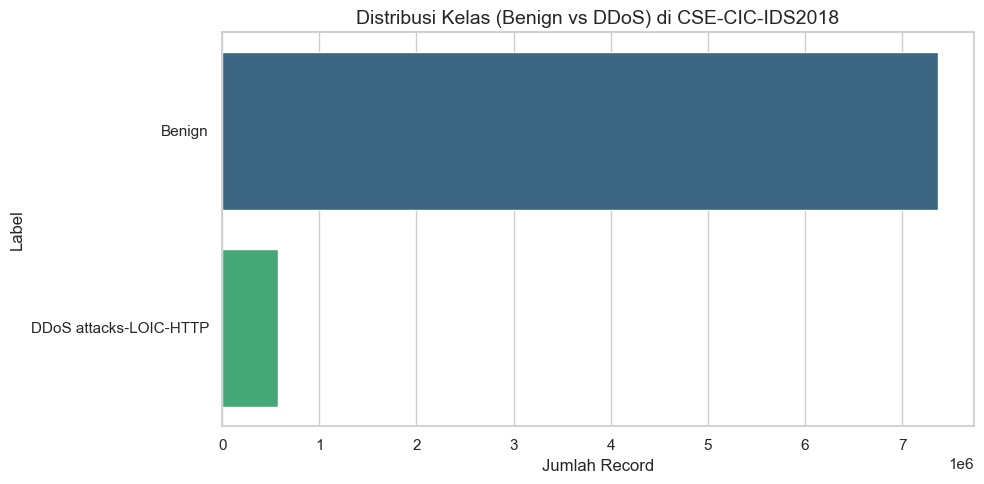

In [3]:
# ================================================
# TAHAP 3: Eksplorasi Dasar & Cek Imbalance
# ================================================

print("=== Informasi Dataset ===")
df.info()

print("\n=== 5 Baris Pertama ===")
display(df.head()) # Menggunakan display() agar tampilan tabel di Jupyter/Colab lebih rapi

print("\n=== Distribusi Kelas (Label) ===")
print(df['Label'].value_counts())

# Visualisasi Ketimpangan Data
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='Label', order=df['Label'].value_counts().index, palette='viridis')
plt.title('Distribusi Kelas (Benign vs DDoS) di CSE-CIC-IDS2018', fontsize=14)
plt.xlabel('Jumlah Record', fontsize=12)
plt.ylabel('Label', fontsize=12)
plt.tight_layout()
plt.show()

In [4]:
# ================================================
# TAHAP 4: Cleaning Awal (Infinity & NaN)
# ================================================

print("Memeriksa dan membersihkan nilai Infinity/NaN...")
# Ganti Infinity jadi NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Cek berapa NaN (Opsional, untuk monitoring)
nan_counts = df.isna().sum()
print("Jumlah NaN per kolom yang bermasalah:")
print(nan_counts[nan_counts > 0])

# Drop baris yang ada NaN 
df_clean = df.dropna()
print(f"\nData setelah cleaning: {df_clean.shape[0]:,} baris")

Memeriksa dan membersihkan nilai Infinity/NaN...
Jumlah NaN per kolom yang bermasalah:
Flow Byts/s    59453
Flow Pkts/s    59453
dtype: int64

Data setelah cleaning: 7,889,295 baris


In [5]:
# ================================================
# TAHAP 5: Drop Kolom & Mapping Label
# ================================================

# Drop kolom identitas yang bisa menyebabkan overfitting
cols_to_drop = ['Flow ID', 'Src IP', 'Dst IP', 'Timestamp']
existing_cols = [col for col in cols_to_drop if col in df_clean.columns]
df_model = df_clean.drop(columns=existing_cols)

print(f"\nKolom yang di-drop: {existing_cols}")

# Karena file 02-20-2018 fokus pada DDoS LOIC-HTTP, kita ubah jadi Binary (0 = Benign, 1 = Attack)
df_model['Label_Binary'] = df_model['Label'].apply(lambda x: 0 if x == 'Benign' else 1)

# Pisahkan Fitur (X) dan Target (y)
X = df_model.drop(columns=['Label', 'Label_Binary'])
y = df_model['Label_Binary']


Kolom yang di-drop: ['Flow ID', 'Src IP', 'Dst IP', 'Timestamp']


In [6]:
# ================================================
# TAHAP 6: TRAIN-TEST SPLIT (Mencegah Data Leakage)
# ================================================

print("\nMelakukan Train-Test Split (Karantina Test Set)...")
# Kita pisahkan 80% Train dan 20% Test. Parameter 'stratify=y' memastikan proporsi kelas tetap sama.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Karantina Data Berhasil!")
print(f"Shape Data Latih (Train Set) : {X_train.shape[0]:,} ")
print(f"Shape Data Uji (Test Set)    : {X_test.shape[0]:,}")

# Cek distribusi di Train Set
print("\nDistribusi Kelas di Train Set:")
print(y_train.value_counts())


Melakukan Train-Test Split (Karantina Test Set)...
Karantina Data Berhasil!
Shape Data Latih (Train Set) : 6,311,436 
Shape Data Uji (Test Set)    : 1,577,859

Distribusi Kelas di Train Set:
Label_Binary
0    5850483
1     460953
Name: count, dtype: int64


In [7]:
# ================================================
# TAHAP 7: Normalisasi (Scaling) HANYA Berdasarkan Train Set
# ================================================
print("Melakukan Normalisasi Fitur...")

# Kita fit scaler HANYA pada X_train untuk mencegah kebocoran informasi distribusi data
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Transform X_test menggunakan scaler yang sudah di-fit oleh X_train
X_test_scaled = scaler.transform(X_test)

# Kembalikan ke format DataFrame agar mudah diproses
feature_cols = X_train.columns
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=feature_cols)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=feature_cols)

print("Normalisasi selesai!")

Melakukan Normalisasi Fitur...
Normalisasi selesai!


In [8]:
# ================================================
# TAHAP 8: Ekstrak Data Minoritas (DDoS) untuk CTGAN
# ================================================
# Gabungkan X_train_scaled dan y_train sementara untuk filtering
train_combined = X_train_scaled_df.copy()
# Reset index y_train agar sejajar dengan baris X_train_scaled_df
train_combined['Label_Binary'] = y_train.reset_index(drop=True)

# Ambil HANYA kelas serangan (1)
df_attack_train = train_combined[train_combined['Label_Binary'] == 1].drop(columns=['Label_Binary'])

print(f"\nJumlah total data serangan di Train Set: {df_attack_train.shape[0]:,} baris")

# Ambil sampel untuk training CTGAN (50.000 sudah representatif dan ramah RAM laptop)
sample_size = 50000
X_attack_gan = df_attack_train.sample(n=sample_size, random_state=42)

print(f"Data yang akan dilatih ke CTGAN: {X_attack_gan.shape[0]:,} baris")


Jumlah total data serangan di Train Set: 460,953 baris
Data yang akan dilatih ke CTGAN: 50,000 baris


In [9]:
# ================================================
# TAHAP 9: Simpan Data Train & Test (Backup Eksperimen)
# ================================================
print("Menyimpan dataset yang sudah dipisah dan dinormalisasi...")

# Simpan dataset yang sudah aman dari data leakage
X_train_scaled_df.to_csv('X_train_scaled.csv', index=False)
X_test_scaled_df.to_csv('X_test_scaled.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

# Simpan data minoritas yang akan masuk ke CTGAN
X_attack_gan.to_csv('X_attack_gan.csv', index=False)

print("File berhasil disimpan:")
print("- X_train_scaled.csv")
print("- X_test_scaled.csv")
print("- y_train.csv")
print("- y_test.csv")
print("- X_attack_gan.csv")

Menyimpan dataset yang sudah dipisah dan dinormalisasi...
File berhasil disimpan:
- X_train_scaled.csv
- X_test_scaled.csv
- y_train.csv
- y_test.csv
- X_attack_gan.csv


In [10]:
# ================================================
# TAHAP 10: Training CTGAN (Hanya menggunakan X_attack_gan)
# ================================================
print("\nPersiapan Training CTGAN...")

# Set seed agar hasil generate bisa direproduksi secara konsisten
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Inisialisasi arsitektur CTGAN (Sesuai dengan eksperimen Anda)
ctgan_model = CTGAN(
    epochs=100,
    batch_size=500,
    generator_dim=(256, 256),
    discriminator_dim=(256, 256),
    verbose=True
)

print("Mulai training CTGAN...")

# Fit model HANYA pada sampel serangan dari Train Set
ctgan_model.fit(X_attack_gan)

print("Training CTGAN selesai dengan sukses!")


Persiapan Training CTGAN...
Mulai training CTGAN...


Gen. (+00.13) | Discrim. (+00.68): 100%|█████████████████████████████████████████████| 100/100 [30:28<00:00, 18.28s/it]

Training CTGAN selesai dengan sukses!


In [11]:
# ================================================
# TAHAP 11: Generate Data Sintetis
# ================================================
print("Membangkitkan data serangan sintetis...")

# Membangkitkan 100.000 data sintetis (sesuai script awal Anda)
num_synthetic = 100000 
synthetic_data = ctgan_model.sample(num_synthetic)

# Simpan sebagai backup
synthetic_data.to_csv('synthetic_DDoS_CTGAN.csv', index=False)

print(f"Berhasil membangkitkan {num_synthetic:,} baris data sintetis!")

Membangkitkan data serangan sintetis...
Berhasil membangkitkan 100,000 baris data sintetis!


In [12]:
# ================================================
# TAHAP 12: Balancing Dataset (HANYA PADA TRAIN SET)
# ================================================
print("\nMenyeimbangkan Train Set...")

# 1. Gabungkan kembali X_train dan y_train sementara untuk mempermudah manipulasi
train_combined = X_train_scaled_df.copy()
train_combined['Label_Binary'] = y_train.reset_index(drop=True)

# 2. Pisahkan kelas Benign (0) dan Attack (1) asli dari Train Set
df_train_benign = train_combined[train_combined['Label_Binary'] == 0]
df_train_attack = train_combined[train_combined['Label_Binary'] == 1]

# 3. Siapkan data sintetis (tambahkan kolom Label_Binary bernilai 1)
synthetic_data['Label_Binary'] = 1

# 4. Gabungkan serangan asli (dari train) + serangan sintetis
df_attack_combined = pd.concat([df_train_attack, synthetic_data], ignore_index=True)

# 5. Undersampling kelas Benign agar jumlahnya SAMA PERSIS dengan total serangan gabungan
# (Ini akan menghasilkan komposisi 50:50 yang sempurna)
df_benign_sampled = df_train_benign.sample(n=len(df_attack_combined), random_state=42)

# 6. Gabungkan menjadi Balanced Train Set akhir
df_train_balanced = pd.concat([df_benign_sampled, df_attack_combined], ignore_index=True)

# 7. Pisahkan kembali Fitur dan Target untuk persiapan masuk ke Hybrid CNN-LSTM
X_train_bal = df_train_balanced.drop(columns=['Label_Binary'])
y_train_bal = df_train_balanced['Label_Binary']

print("\nBalanced Train Set BERHASIL dibuat!")
print(f"Total baris data latih: {df_train_balanced.shape[0]:,}")
print("Distribusi Kelas (Seimbang):")
print(df_train_balanced['Label_Binary'].value_counts())


Menyeimbangkan Train Set...

Balanced Train Set BERHASIL dibuat!
Total baris data latih: 1,121,906
Distribusi Kelas (Seimbang):
Label_Binary
0    560953
1    560953
Name: count, dtype: int64


In [13]:
# ================================================
# TAHAP 13: Persiapan & Training Model Hybrid CNN-LSTM
# ================================================
print("Mempersiapkan data untuk model Deep Learning...")

# 1. Konversi ke array Numpy dan ubah bentuk (Reshape) untuk CNN
# Layer Conv1D mengharapkan input 3 dimensi: (jumlah_sampel, jumlah_fitur, 1)
X_train_dl = X_train_bal.values.reshape((X_train_bal.shape[0], X_train_bal.shape[1], 1))
X_test_dl = X_test_scaled_df.values.reshape((X_test_scaled_df.shape[0], X_test_scaled_df.shape[1], 1))

# 2. Encoding Target menjadi One-Hot Encoding (Sesuai output 2 neuron / Softmax)
from tensorflow.keras.utils import to_categorical
y_train_cat = to_categorical(y_train_bal)
y_test_cat = to_categorical(y_test)

print(f"Shape Input Latih (Train) : {X_train_dl.shape}")
print(f"Shape Input Uji (Test)    : {X_test_dl.shape}")

# 3. Membangun Arsitektur Hybrid CNN-LSTM
print("\nMembangun arsitektur Hybrid CNN-LSTM...")
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    # Modul CNN (Spatial Feature Extraction)
    Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(X_train_dl.shape[1], 1)),
    MaxPooling1D(pool_size=2),
    Dropout(0.3),

    # Modul LSTM (Temporal Sequence Learning)
    LSTM(128, return_sequences=True),
    Dropout(0.3),
    LSTM(64),

    # Modul Klasifikasi (Fully Connected Layer)
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(2, activation='softmax') # 2 Kelas: 0 (Benign) dan 1 (Attack)
])

# Kompilasi Model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Tampilkan ringkasan arsitektur (jumlah parameter)
model.summary()

# 4. Pelatihan Model (Training)
print("\nMemulai pelatihan model (Mungkin memakan waktu cukup lama)...")
# EarlyStopping mencegah overfitting jika val_loss tidak membaik selama 5 epoch berturut-turut
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_train_dl, y_train_cat,
    epochs=50, 
    batch_size=512,
    validation_split=0.2, # 20% dari Train Set disisihkan untuk validasi per-epoch
    callbacks=[early_stop],
    verbose=1
)

print("\nPelatihan Model Hybrid CNN-LSTM Selesai!")

Mempersiapkan data untuk model Deep Learning...
Shape Input Latih (Train) : (1121906, 79, 1)
Shape Input Uji (Test)    : (1577859, 79, 1)

Membangun arsitektur Hybrid CNN-LSTM...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 77, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 38, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 38, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 38, 128)             │          98,816 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 38, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 2)                   │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 152,770 (596.76 KB)

 Trainable params: 152,770 (596.76 KB)

 Non-trainable params: 0 (0.00 B)


Memulai pelatihan model (Mungkin memakan waktu cukup lama)...
Epoch 1/50
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 370s 209ms/step - accuracy: 0.9682 - loss: 0.0805 - val_accuracy: 0.9556 - val_loss: 0.2346
Epoch 2/50
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 352s 201ms/step - accuracy: 0.9910 - loss: 0.0295 - val_accuracy: 0.9632 - val_loss: 0.2315
Epoch 3/50
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 352s 201ms/step - accuracy: 0.9964 - loss: 0.0122 - val_accuracy: 0.9737 - val_loss: 0.2191
Epoch 4/50
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 351s 200ms/step - accuracy: 0.9976 - loss: 0.0082 - val_accuracy: 0.9804 - val_loss: 0.1782
Epoch 5/50
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 352s 201ms/step - accuracy: 0.9980 - loss: 0.0069 - val_accuracy: 0.9721 - val_loss: 0.2287
Epoch 6/50
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 354s 202ms/step - accuracy: 0.9975 - loss: 0.0084 - val_accuracy: 0.9685 - val_loss: 0.2055
Epoch 7/50
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 361s 206ms/step - accuracy: 0.9986 - loss: 0.0048 - val_accuracy: 0.9740 - val_loss: 0.2171

Mengevaluasi model pada Data Uji (Test Set)...
49309/49309 ━━━━━━━━━━━━━━━━━━━━ 443s 9ms/step

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

  Benign (0)     0.9998    0.9986    0.9992   1462621
  Attack (1)     0.9824    0.9975    0.9899    115238

    accuracy                         0.9985   1577859
   macro avg     0.9911    0.9981    0.9945   1577859
weighted avg     0.9985    0.9985    0.9985   1577859


F1-Score (Weighted): 0.9985


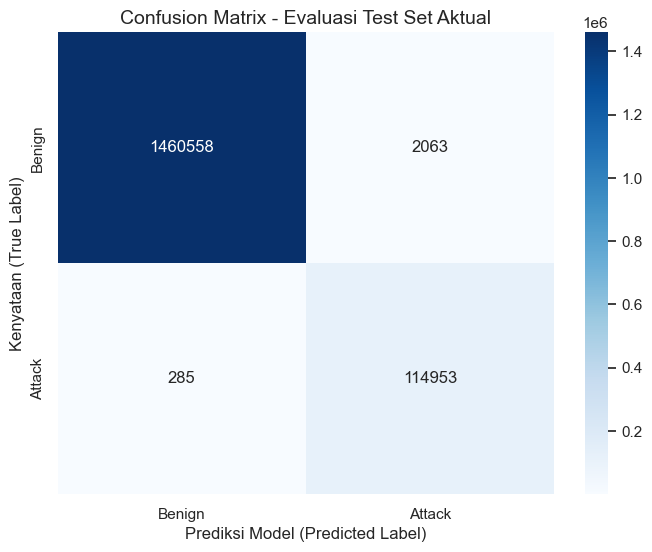

In [ ]:
# ================================================
# TAHAP 14: Evaluasi Model pada Test Set (Karantina)
# ================================================
print("Mengevaluasi model pada Data Uji (Test Set)...")
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# 1. Lakukan Prediksi pada Data Uji yang belum pernah dilihat model
y_pred = model.predict(X_test_dl)
y_pred_class = np.argmax(y_pred, axis=1) # Ubah probabilitas softmax menjadi label 0 atau 1
y_test_class = y_test.values             # y_test asli dari awal (sudah bernilai 0 dan 1)

# 2. Cetak Metrik Lengkap
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test_class, y_pred_class, target_names=['Benign (0)', 'Attack (1)'], digits=4))

f1 = f1_score(y_test_class, y_pred_class, average='weighted')
print(f"\nF1-Score (Weighted): {f1:.4f}")

# 3. Visualisasi Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test_class, y_pred_class)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Attack'],
            yticklabels=['Benign', 'Attack'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Evaluasi Test Set Aktual', fontsize=14)
plt.show()


Menyimpan model dan grafik pelatihan untuk manuskrip/laporan...
Model berhasil disimpan sebagai 'hybrid_cnn_lstm_model_final'


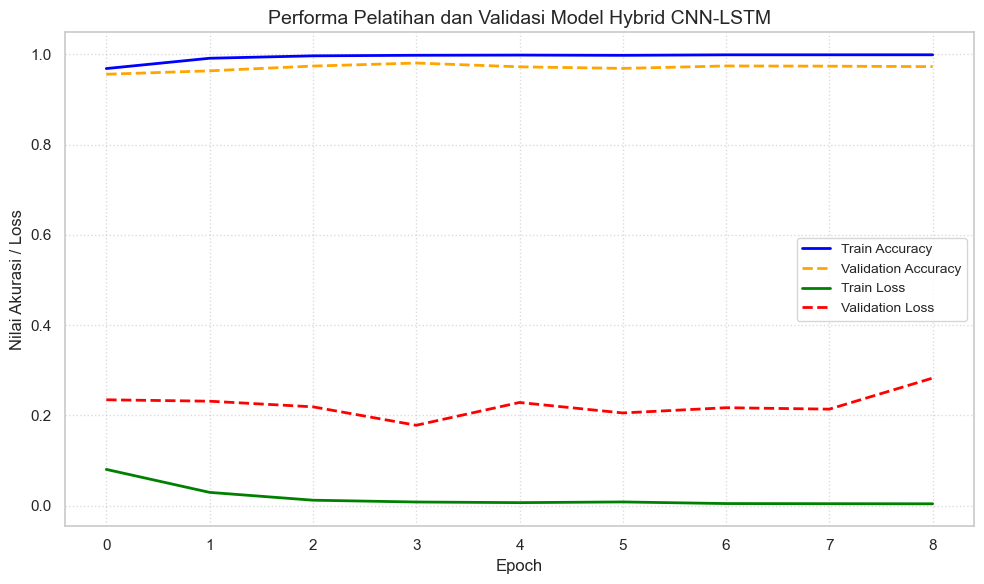

Grafik evaluasi berhasil disimpan sebagai 'combined_training_history_final.png'


In [ ]:
# ================================================
# TAHAP 15: Simpan Model dan Plot Training History
# ================================================
print("\nMenyimpan model dan grafik pelatihan untuk manuskrip/laporan...")

# 1. Simpan Model
model.save('hybrid_cnn_lstm_model_final.h5')
model.save('hybrid_cnn_lstm_model_final.keras')
print("Model berhasil disimpan sebagai 'hybrid_cnn_lstm_model_final'")

# 2. Plot Grafik Akurasi dan Loss (Resolusi 300 DPI untuk Jurnal)
if 'history' in globals() or 'history' in locals():
    plt.figure(figsize=(10, 6))

    # Plot ke-4 garis secara bersamaan
    plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue', linewidth=2)
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2, linestyle='--')
    plt.plot(history.history['loss'], label='Train Loss', color='green', linewidth=2)
    plt.plot(history.history['val_loss'], label='Validation Loss', color='red', linewidth=2, linestyle='--')

    plt.title('Performa Pelatihan dan Validasi Model Hybrid CNN-LSTM', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Accuracy / Loss Value', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc='center right', fontsize=10)

    plt.tight_layout()
    plt.savefig('combined_training_history_final.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("Grafik evaluasi berhasil disimpan sebagai 'combined_training_history_final.png'")
else:
    print("Variabel 'history' tidak ditemukan.")